TensorFlow version: 2.21.0
Total tokens: 3780
Vocabulary size: 78
Training input shape: (3774, 6)
Target shape: (3774, 6)

TRANSFORMER MODEL SUMMARY


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 6)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ positional_embedding_1          │ (None, 6, 32)          │         2,688 │
│ (PositionalEmbedding)           │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_1             │ (None, 6, 32)          │         8,544 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6, 78)          │         2,574 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,806 (53.93 KB)

 Trainable params: 13,806 (53.93 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 56ms/step - loss: 2.3806 - sparse_categorical_accuracy: 0.5424 - val_loss: 1.2434 - val_sparse_categorical_accuracy: 0.7143
Epoch 2/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.9764 - sparse_categorical_accuracy: 0.7597 - val_loss: 0.7463 - val_sparse_categorical_accuracy: 0.8360
Epoch 3/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.6047 - sparse_categorical_accuracy: 0.8712 - val_loss: 0.4634 - val_sparse_categorical_accuracy: 0.9220
Epoch 4/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.3874 - sparse_categorical_accuracy: 0.9237 - val_loss: 0.3098 - val_sparse_categorical_accuracy: 0.9339
Epoch 5/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.2761 - sparse_categorical_accuracy: 0.9315 - val_loss: 0.2365 - val_sparse_categorical_accuracy: 0.9339
Epoch 6/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.2225 - sparse_categorical_accuracy: 0.9308 - val_loss: 0.2018 - val_sparse_categorical_accuracy: 0.9325
Epoch 7/1

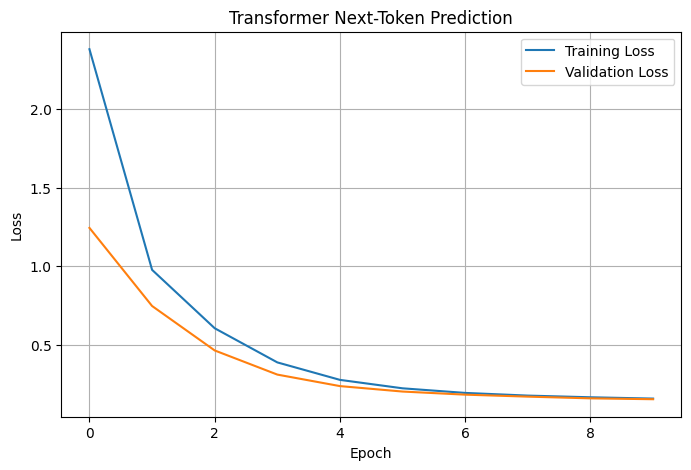


SAMPLE PREDICTIONS
Input text: artificial intelligence
Predicted next token: through
Input text: self attention
Predicted next token: to
Input text: language models
Predicted next token: predict

MODEL EVALUATION
Training-data loss: 0.1530
Training-data token accuracy: 93.25%

Model saved as transformer_next_token.keras
PROJECT EXECUTED SUCCESSFULLY!


In [2]:

import re
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model


np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)

text = """
artificial intelligence helps computers learn from data
machine learning is a part of artificial intelligence
deep learning uses neural networks to learn complex patterns
a neural network learns patterns from training examples
transformers use attention to understand relationships between tokens
self attention helps a model focus on important words
language models predict the next token in a sequence
a transformer processes tokens using self attention
python is a popular programming language
students learn artificial intelligence through practical projects
data science combines statistics programming and machine learning
computers can process text images and numerical data
a model learns by adjusting its trainable parameters
training data helps a neural network learn useful patterns
attention allows tokens to exchange contextual information
next token prediction is used in language modeling
"""
text = (text.strip().lower() + "\n") * 30

tokens = re.findall(r"\b[a-z]+\b|[.,!?]", text)

vocabulary = sorted(set(tokens))
word_to_id = {word: i + 1 for i, word in enumerate(vocabulary)}
id_to_word = {i: word for word, i in word_to_id.items()}

VOCAB_SIZE = len(vocabulary) + 1
token_ids = [word_to_id[word] for word in tokens]

print("Total tokens:", len(token_ids))
print("Vocabulary size:", VOCAB_SIZE)

SEQ_LEN = 6

X = []
y = []

for i in range(len(token_ids) - SEQ_LEN):

    X.append(token_ids[i:i + SEQ_LEN])

    y.append(token_ids[i + 1:i + SEQ_LEN + 1])

X = np.array(X, dtype=np.int32)
y = np.array(y, dtype=np.int32)

print("Training input shape:", X.shape)
print("Target shape:", y.shape)

class PositionalEmbedding(layers.Layer):
    def __init__(self, vocab_size, seq_len, embed_dim):
        super().__init__()
        self.token_embedding = layers.Embedding(
            vocab_size, embed_dim
        )
        self.position_embedding = layers.Embedding(
            seq_len, embed_dim
        )

    def call(self, inputs):
        positions = tf.range(start=0, limit=tf.shape(inputs)[1])
        token_vectors = self.token_embedding(inputs)
        position_vectors = self.position_embedding(positions)

        return token_vectors + position_vectors

class TransformerBlock(layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim):
        super().__init__()

        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads
        )

        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)

        self.feed_forward = tf.keras.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(embed_dim)
        ])

    def call(self, inputs, training=None):

        attention_output = self.attention(
            query=inputs,
            value=inputs,
            key=inputs,
            use_causal_mask=True,
            training=training
        )

        x = self.norm1(inputs + attention_output)

        ff_output = self.feed_forward(x, training=training)

        return self.norm2(x + ff_output)


EMBED_DIM = 32

inputs = layers.Input(shape=(SEQ_LEN,), dtype=tf.int32)

x = PositionalEmbedding(
    VOCAB_SIZE, SEQ_LEN, EMBED_DIM
)(inputs)

x = TransformerBlock(
    embed_dim=EMBED_DIM,
    num_heads=2,
    ff_dim=64
)(x)

outputs = layers.Dense(VOCAB_SIZE)(x)

model = Model(inputs=inputs, outputs=outputs)

model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=["sparse_categorical_accuracy"]
)

print("\nTRANSFORMER MODEL SUMMARY")
model.summary()

history = model.fit(
    X,
    y,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)


plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Transformer Next-Token Prediction")
plt.legend()
plt.grid(True)
plt.show()


def predict_next_token(prompt):
    prompt_tokens = re.findall(r"\b[a-z]+\b|[.,!?]", prompt.lower())

    known_tokens = [
        word_to_id[word]
        for word in prompt_tokens
        if word in word_to_id
    ]

    if not known_tokens:
        print("No known words found in the prompt.")
        return


    context = known_tokens[-SEQ_LEN:]


    context = [0] * (SEQ_LEN - len(context)) + context

    input_array = np.array([context], dtype=np.int32)

    logits = model.predict(input_array, verbose=0)[0, -1]


    logits[0] = -1e9

    predicted_id = int(np.argmax(logits))
    predicted_word = id_to_word[predicted_id]

    print("Input text:", prompt)
    print("Predicted next token:", predicted_word)

    return predicted_word


print("\nSAMPLE PREDICTIONS")
predict_next_token("artificial intelligence")
predict_next_token("self attention")
predict_next_token("language models")



results = model.evaluate(X, y, verbose=0)

print("\nMODEL EVALUATION")
print(f"Training-data loss: {results[0]:.4f}")
print(f"Training-data token accuracy: {results[1] * 100:.2f}%")

model.save("transformer_next_token.keras")

print("\nModel saved as transformer_next_token.keras")
print("PROJECT EXECUTED SUCCESSFULLY!")